In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, classification_report)
import joblib
import warnings
warnings.filterwarnings('ignore')

print("✅ All libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

✅ All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 2
# STEP 2: DATASET LOADING
# ============================================

# INSTRUCTIONS:
# 1. Download CICIDS2017 from Kaggle at home
# 2. Upload CSV files to Google Drive in this folder:
#    My Drive > SmartGuardAI > data
# 3. Then run this cell

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Path to your dataset folder
DATA_PATH = '/content/drive/MyDrive/SmartGuardAI/data/'

print("✅ Google Drive mounted successfully!")
print(f"📂 Dataset folder path: {DATA_PATH}")
print("👉 Next: We will load CSV files from this folder")

Mounted at /content/drive
✅ Google Drive mounted successfully!
📂 Dataset folder path: /content/drive/MyDrive/SmartGuardAI/data/
👉 Next: We will load CSV files from this folder


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 2
# STEP 3: VERIFY DRIVE FOLDER
# ============================================

import os

# Check if our folder exists
folder_path = '/content/drive/MyDrive/SmartGuardAI/data/'

if os.path.exists(folder_path):
    print("✅ Folder exists and is accessible!")
    files = os.listdir(folder_path)
    if len(files) == 0:
        print("📂 Folder is empty — dataset not uploaded yet")
        print("👉 At home: Download CICIDS2017 and upload CSVs here")
    else:
        print(f"📁 Files found: {len(files)}")
        for f in files:
            print(f"   → {f}")
else:
    print("❌ Folder not found — please create it in Google Drive first")
    print("   Path needed: My Drive > SmartGuardAI > data")


✅ Folder exists and is accessible!
📁 Files found: 1
   → cicids2017_cleaned.csv


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 2
# STEP 4: LOAD DATASET FILES
# ============================================

import os
import pandas as pd

DATA_PATH = '/content/drive/MyDrive/SmartGuardAI/data/'

# Get all CSV files from folder
csv_files = [f for f in os.listdir(DATA_PATH) if f.endswith('.csv')]

print(f"📁 CSV files found: {len(csv_files)}")
for f in csv_files:
    size = os.path.getsize(DATA_PATH + f) / (1024*1024)
    print(f"   → {f}  ({size:.1f} MB)")

# Load all CSV files into one dataframe
print("\n⏳ Loading all files... (may take a few minutes)")

df_list = []
for f in csv_files:
    temp = pd.read_csv(DATA_PATH + f, encoding='utf-8', low_memory=False)
    print(f"   ✅ {f} — {len(temp)} rows loaded")
    df_list.append(temp)

# Combine all files
df = pd.concat(df_list, ignore_index=True)

print(f"\n✅ All files combined!")
print(f"📊 Total rows    : {len(df):,}")
print(f"📊 Total columns : {len(df.columns)}")
print(f"📊 Dataset shape : {df.shape}")

📁 CSV files found: 1
   → cicids2017_cleaned.csv  (684.0 MB)

⏳ Loading all files... (may take a few minutes)
   ✅ cicids2017_cleaned.csv — 2520751 rows loaded

✅ All files combined!
📊 Total rows    : 2,520,751
📊 Total columns : 53
📊 Dataset shape : (2520751, 53)


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 2
# STEP 5: DATASET EXPLORATION
# ============================================

# First 5 rows dekho
print("📋 FIRST 5 ROWS:")
print(df.head())

# Column names dekho
print("\n📊 ALL COLUMNS:")
for i, col in enumerate(df.columns):
    print(f"   {i+1}. {col}")

# Attack types dekho
print("\n🎯 ATTACK CATEGORIES:")
print(df['Attack Type'].value_counts())

📋 FIRST 5 ROWS:
   Destination Port  Flow Duration  Total Fwd Packets  \
0                22        1266342                 41   
1                22        1319353                 41   
2                22            160                  1   
3                22        1303488                 41   
4             35396             77                  1   

   Total Length of Fwd Packets  Fwd Packet Length Max  Fwd Packet Length Min  \
0                         2664                    456                      0   
1                         2664                    456                      0   
2                            0                      0                      0   
3                         2728                    456                      0   
4                            0                      0                      0   

   Fwd Packet Length Mean  Fwd Packet Length Std  Bwd Packet Length Max  \
0               64.975610             109.864573                    976   
1         

In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 2
# STEP 5: ATTACK CATEGORIES
# ============================================

# Label column ka sahi naam
LABEL_COL = 'Attack Type'

# Attack types dekho
print("🎯 ATTACK CATEGORIES:")
print(df[LABEL_COL].value_counts())

print(f"\n📊 Total Classes: {df[LABEL_COL].nunique()}")
print(f"📊 Label Column: '{LABEL_COL}'")

🎯 ATTACK CATEGORIES:
Attack Type
Normal Traffic    2095057
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Name: count, dtype: int64

📊 Total Classes: 7
📊 Label Column: 'Attack Type'


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 2
# STEP 6: DATA QUALITY CHECK
# ============================================

LABEL_COL = 'Attack Type'

# Missing values check
print("🔍 MISSING VALUES:")
missing = df.isnull().sum()
missing_cols = missing[missing > 0]
if len(missing_cols) == 0:
    print("   ✅ No missing values found!")
else:
    print(missing_cols)

# Infinite values check
print("\n🔍 INFINITE VALUES:")
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
inf_count = np.isinf(df[numeric_cols]).sum().sum()
if inf_count == 0:
    print("   ✅ No infinite values found!")
else:
    print(f"   ⚠️ Found {inf_count} infinite values")

# Duplicate rows check
print("\n🔍 DUPLICATE ROWS:")
duplicates = df.duplicated().sum()
print(f"   Duplicate rows: {duplicates:,}")

# Dataset summary
print("\n📊 DATASET SUMMARY:")
print(f"   Total rows    : {len(df):,}")
print(f"   Total columns : {len(df.columns)}")
print(f"   Features      : {len(df.columns) - 1}")
print(f"   Label column  : '{LABEL_COL}'")

🔍 MISSING VALUES:
   ✅ No missing values found!

🔍 INFINITE VALUES:
   ✅ No infinite values found!

🔍 DUPLICATE ROWS:
   Duplicate rows: 161

📊 DATASET SUMMARY:
   Total rows    : 2,520,751
   Total columns : 53
   Features      : 52
   Label column  : 'Attack Type'


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 2
# STEP 7: DATA CLEANING
# ============================================

LABEL_COL = 'Attack Type'

# Step 1 - Duplicates remove karo
print(f"⏳ Removing {df.duplicated().sum()} duplicate rows...")
df = df.drop_duplicates()
print(f"✅ Duplicates removed!")
print(f"📊 Rows after cleaning: {len(df):,}")

# Step 2 - Dataset ko sample karo (2.5M bohot zyada hai training ke liye)
# Har class se equal samples lenge
print("\n⏳ Creating balanced sample...")

SAMPLE_PER_CLASS = 10000  # Har attack type se 10,000 rows

df_sampled = df.groupby(LABEL_COL).apply(
    lambda x: x.sample(min(len(x), SAMPLE_PER_CLASS), random_state=42)
).reset_index(drop=True)

print(f"✅ Balanced sample created!")
print(f"\n📊 SAMPLE DISTRIBUTION:")
print(df_sampled[LABEL_COL].value_counts())
print(f"\n📊 Total sample rows: {len(df_sampled):,}")

In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 3
# STEP 1: PREPARE FEATURES
# ============================================

LABEL_COL = 'Attack Type'

# X = Features (input), y = Labels (output)
X = df_sampled.drop(columns=[LABEL_COL])
y = df_sampled[LABEL_COL]

print(f"✅ Features (X) shape : {X.shape}")
print(f"✅ Labels (y) shape   : {y.shape}")

# Label encoding - ML model numbers samajhta hai, strings nahi
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f"\n📊 LABEL ENCODING:")
for i, class_name in enumerate(le.classes_):
    print(f"   {i} → {class_name}")

# Train/Test Split - 80% training, 20% testing
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"\n📊 TRAIN/TEST SPLIT:")
print(f"   Training rows : {len(X_train):,}")
print(f"   Testing rows  : {len(X_test):,}")

✅ Features (X) shape : (53241, 52)
✅ Labels (y) shape   : (53241,)

📊 LABEL ENCODING:
   0 → Bots
   1 → Brute Force
   2 → DDoS
   3 → DoS
   4 → Normal Traffic
   5 → Port Scanning
   6 → Web Attacks

📊 TRAIN/TEST SPLIT:
   Training rows : 42,592
   Testing rows  : 10,649


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 3
# STEP 2: FEATURE SCALING
# ============================================

from sklearn.preprocessing import StandardScaler

# Scaler banao
scaler = StandardScaler()

# Sirf training data pe fit karo — test data pe nahi
# (Data leakage prevent karne ke liye)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Feature scaling complete!")
print(f"   Training set shape : {X_train_scaled.shape}")
print(f"   Testing set shape  : {X_test_scaled.shape}")
print(f"\n📊 Sample scaled values (first row, first 5 features):")
print(f"   {X_train_scaled[0][:5]}")
print("\n✅ Ready for ML Training!")

✅ Feature scaling complete!
   Training set shape : (42592, 52)
   Testing set shape  : (10649, 52)

📊 Sample scaled values (first row, first 5 features):
   [-0.33535744 -0.22107387  0.98621336  0.27333676  0.7889074 ]

✅ Ready for ML Training!


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 3
# STEP 3: TRAIN RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestClassifier
import time

print("⏳ Training Random Forest... (2-3 minutes lagenge)")
start_time = time.time()

# Model banao aur train karo
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1  # Saare CPU cores use karo
)

rf_model.fit(X_train_scaled, y_train)

end_time = time.time()
training_time = round(end_time - start_time, 2)

print(f"✅ Random Forest Training Complete!")
print(f"⏱️ Training time: {training_time} seconds")

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)

# Accuracy
from sklearn.metrics import accuracy_score
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"🎯 Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

⏳ Training Random Forest... (2-3 minutes lagenge)
✅ Random Forest Training Complete!
⏱️ Training time: 10.03 seconds
🎯 Random Forest Accuracy: 99.74%


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 3
# STEP 4: TRAIN DECISION TREE
# ============================================

from sklearn.tree import DecisionTreeClassifier

print("⏳ Training Decision Tree...")
start_time = time.time()

# Model banao aur train karo
dt_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

dt_model.fit(X_train_scaled, y_train)

end_time = time.time()
training_time = round(end_time - start_time, 2)

print(f"✅ Decision Tree Training Complete!")
print(f"⏱️ Training time: {training_time} seconds")

# Predictions
y_pred_dt = dt_model.predict(X_test_scaled)

# Accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(f"🎯 Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")

# Comparison
print(f"\n📊 MODEL COMPARISON:")
print(f"   Random Forest : {rf_accuracy * 100:.2f}%")
print(f"   Decision Tree : {dt_accuracy * 100:.2f}%")

if rf_accuracy > dt_accuracy:
    print(f"\n🏆 Winner: Random Forest!")
else:
    print(f"\n🏆 Winner: Decision Tree!")

⏳ Training Decision Tree...
✅ Decision Tree Training Complete!
⏱️ Training time: 1.07 seconds
🎯 Decision Tree Accuracy: 99.65%

📊 MODEL COMPARISON:
   Random Forest : 99.74%
   Decision Tree : 99.65%

🏆 Winner: Random Forest!


📊 RANDOM FOREST — DETAILED REPORT
                precision    recall  f1-score   support

          Bots       0.98      0.99      0.99       390
   Brute Force       1.00      1.00      1.00      1830
          DDoS       1.00      1.00      1.00      2000
           DoS       1.00      1.00      1.00      2000
Normal Traffic       0.99      0.99      0.99      2000
 Port Scanning       1.00      1.00      1.00      2000
   Web Attacks       1.00      0.99      0.99       429

      accuracy                           1.00     10649
     macro avg       1.00      1.00      1.00     10649
  weighted avg       1.00      1.00      1.00     10649

📊 DECISION TREE — DETAILED REPORT
                precision    recall  f1-score   support

          Bots       0.99      0.98      0.99       390
   Brute Force       1.00      1.00      1.00      1830
          DDoS       1.00      1.00      1.00      2000
           DoS       1.00      1.00      1.00      2000
Normal Traffic       0.99      0

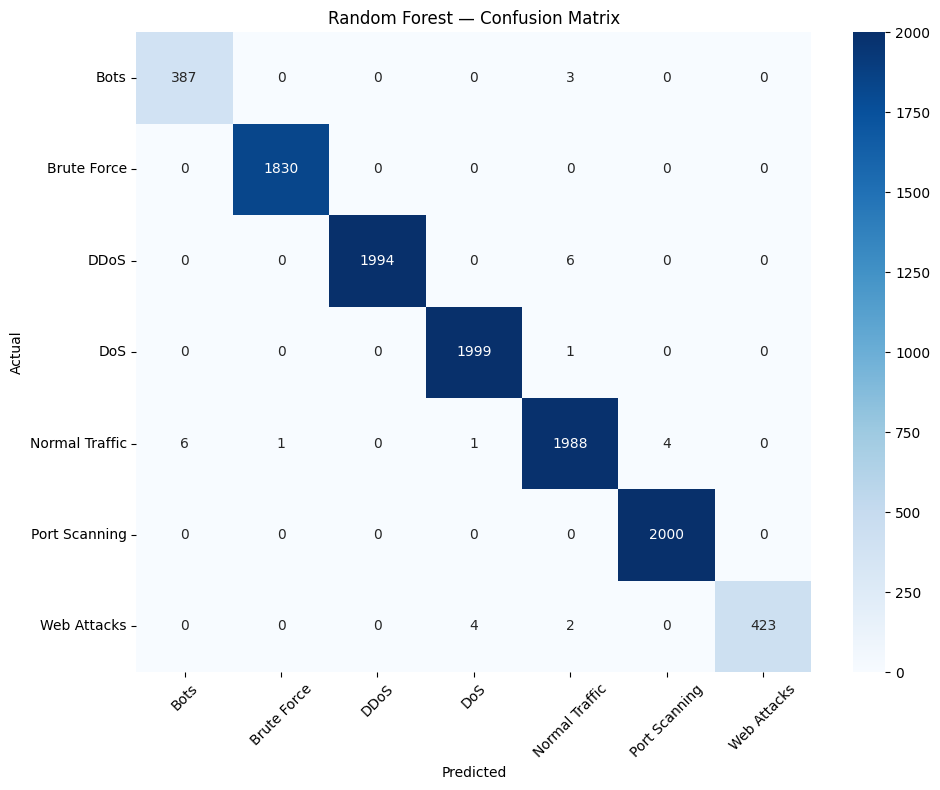

✅ Evaluation Complete!


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 3
# STEP 5: DETAILED EVALUATION
# ============================================

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Classification Report - Random Forest
print("=" * 60)
print("📊 RANDOM FOREST — DETAILED REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred_rf,
      target_names=le.classes_))

# Classification Report - Decision Tree
print("=" * 60)
print("📊 DECISION TREE — DETAILED REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred_dt,
      target_names=le.classes_))

# Confusion Matrix - Random Forest
print("=" * 60)
print("📊 CONFUSION MATRIX — RANDOM FOREST")
print("=" * 60)
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title('Random Forest — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("✅ Evaluation Complete!")

In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 4
# STEP 1: SAVE MODEL FILES
# ============================================

import joblib
import os

# Save folder
SAVE_PATH = '/content/drive/MyDrive/SmartGuardAI/'
os.makedirs(SAVE_PATH, exist_ok=True)

# 1. Best Model save karo
print("⏳ Saving Random Forest model...")
joblib.dump(rf_model, SAVE_PATH + 'smartguard_model.pkl')
print("✅ Model saved!")

# 2. Scaler save karo
print("⏳ Saving scaler...")
joblib.dump(scaler, SAVE_PATH + 'scaler.pkl')
print("✅ Scaler saved!")

# 3. Label Encoder save karo
print("⏳ Saving label encoder...")
joblib.dump(le, SAVE_PATH + 'label_encoder.pkl')
print("✅ Label encoder saved!")

# 4. Feature names save karo
feature_names = list(X.columns)
joblib.dump(feature_names, SAVE_PATH + 'feature_names.pkl')
print("✅ Feature names saved!")

print("\n📁 SAVED FILES:")
for f in os.listdir(SAVE_PATH):
    if f.endswith('.pkl'):
        size = os.path.getsize(SAVE_PATH + f) / (1024*1024)
        print(f"   → {f} ({size:.1f} MB)")

print("\n✅ All files saved to Google Drive!")

⏳ Saving Random Forest model...
✅ Model saved!
⏳ Saving scaler...
✅ Scaler saved!
⏳ Saving label encoder...
✅ Label encoder saved!
✅ Feature names saved!

📁 SAVED FILES:
   → smartguard_model.pkl (8.0 MB)
   → scaler.pkl (0.0 MB)
   → label_encoder.pkl (0.0 MB)
   → feature_names.pkl (0.0 MB)

✅ All files saved to Google Drive!


In [ ]:
# ============================================
# SMARTGUARD AI — PHASE 4
# STEP 2: VERIFY SAVED MODEL
# ============================================

import joblib

SAVE_PATH = '/content/drive/MyDrive/SmartGuardAI/'

# Load saved files
print("⏳ Loading saved model...")
loaded_model    = joblib.load(SAVE_PATH + 'smartguard_model.pkl')
loaded_scaler   = joblib.load(SAVE_PATH + 'scaler.pkl')
loaded_le       = joblib.load(SAVE_PATH + 'label_encoder.pkl')
loaded_features = joblib.load(SAVE_PATH + 'feature_names.pkl')

print("✅ All files loaded successfully!")
print(f"\n📊 Model type    : {type(loaded_model).__name__}")
print(f"📊 Total features: {len(loaded_features)}")
print(f"📊 Attack classes: {list(loaded_le.classes_)}")

# Test prediction
print("\n⏳ Testing prediction...")
sample = X_test_scaled[:5]
predictions = loaded_model.predict(sample)
predicted_labels = loaded_le.inverse_transform(predictions)

print("✅ Test Predictions:")
for i, label in enumerate(predicted_labels):
    actual = loaded_le.inverse_transform([y_test[i]])[0]
    status = "✅" if label == actual else "❌"
    print(f"   {status} Predicted: {label} | Actual: {actual}")

print("\n✅ Model verification complete!")
print("🎯 Model is ready for SmartGuard AI!")

⏳ Loading saved model...
✅ All files loaded successfully!

📊 Model type    : RandomForestClassifier
📊 Total features: 52
📊 Attack classes: ['Bots', 'Brute Force', 'DDoS', 'DoS', 'Normal Traffic', 'Port Scanning', 'Web Attacks']

⏳ Testing prediction...
✅ Test Predictions:
   ✅ Predicted: Normal Traffic | Actual: Normal Traffic
   ✅ Predicted: Port Scanning | Actual: Port Scanning
   ✅ Predicted: Normal Traffic | Actual: Normal Traffic
   ✅ Predicted: DoS | Actual: DoS
   ✅ Predicted: DoS | Actual: DoS

✅ Model verification complete!
🎯 Model is ready for SmartGuard AI!
